# Définition



Soit $\Sigma$ une matrice de covariance **semi-définie positive** (PSD) de taille $n \times n$. Puisqu'elle n'est pas inversible (son déterminant est nul, par exemple à cause d'une colinéarité parfaite entre certaines variables), on ne peut pas utiliser $\Sigma^{-1}$.

On introduit alors son **pseudo-inverse de Moore-Penrose**, noté $\Sigma^+$.

Le **produit scalaire généralisé (ou dégénéré)** associé à ce pseudo-inverse est l'application qui, à tout couple de vecteurs $(x, y) \in \mathbb{R}^n \times \mathbb{R}^n$, associe le nombre réel :


$$\langle x, y \rangle_{\Sigma^+} = x^T \Sigma^+ y$$

---

# Vérification des Axiomes

Pour qu'une telle formulation qualifie un « produit scalaire », elle doit respecter les propriétés structurelles, avec une nuance majeure sur le dernier point :

1. **La Bilinéarité :**
Elle reste parfaitement valide. Par la distributivité du produit matriciel :

$$\langle ax_1 + bx_2, y \rangle_{\Sigma^+} = (ax_1 + bx_2)^T \Sigma^+ y = a(x_1^T \Sigma^+ y) + b(x_2^T \Sigma^+ y) = a\langle x_1, y \rangle_{\Sigma^+} + b\langle x_2, y \rangle_{\Sigma^+}$$


2. **La Symétrie :**
Elle est conservée car le pseudo-inverse d'une matrice symétrique ($\Sigma$) est lui-même symétrique ($(\Sigma^+)^T = \Sigma^+$).

$$\langle x, y \rangle_{\Sigma^+} = x^T \Sigma^+ y = (x^T \Sigma^+ y)^T = y^T (\Sigma^+)^T x = y^T \Sigma^+ x = \langle y, x \rangle_{\Sigma^+}$$


3. **La Positivité Semi-Définie (Le changement majeur) :**
Puisque $\Sigma^+$ est une matrice semi-définie positive, on a bien la positivité large :

$$\langle x, x \rangle_{\Sigma^+} = x^T \Sigma^+ x \ge 0$$



*Cependant*, l'implication stricte d'un produit scalaire classique ($= 0 \implies x = 0$) **disparaît**.
On peut avoir $\langle x, x \rangle_{\Sigma^+} = 0$ pour un vecteur **non nul** $x$, si et seulement si $x$ appartient au **noyau (kernel)** de $\Sigma$ (c'est-à-dire $\Sigma x = 0$). Concrètement, cela signifie que $x$ représente une combinaison linéaire de variables parfaitement redondantes.

---

# Conséquence sur la Distance

Ce produit scalaire dégénéré induit directement la **distance de Mahalanobis généralisée** :

$$D_M(x, y) = \sqrt{\langle x - y, x - y \rangle_{\Sigma^+}} = \sqrt{(x - y)^T \Sigma^+ (x - y)}$$

Géométriquement parlant, l'espace n'est plus un ellipsoïde valide dans toutes les directions : il s'est « aplati » (il a une épaisseur nulle selon les axes de redondance parfaite). La distance entre deux points distincts peut donc valoir zéro si leur différence se trouve précisément dans cet espace aplati.

Matrice de covariance Sigma :
 [[ 0.9629 -0.1452  0.2636]
 [-0.1452  3.8259  5.6663]
 [ 0.2636  5.6663  8.6312]]

Valeurs propres de Sigma (notez la première proche de 0) :
 [-5.52884331e-17  1.03509711e+00  1.23848407e+01]

Pseudo-inverse Sigma+ calculé avec succès.


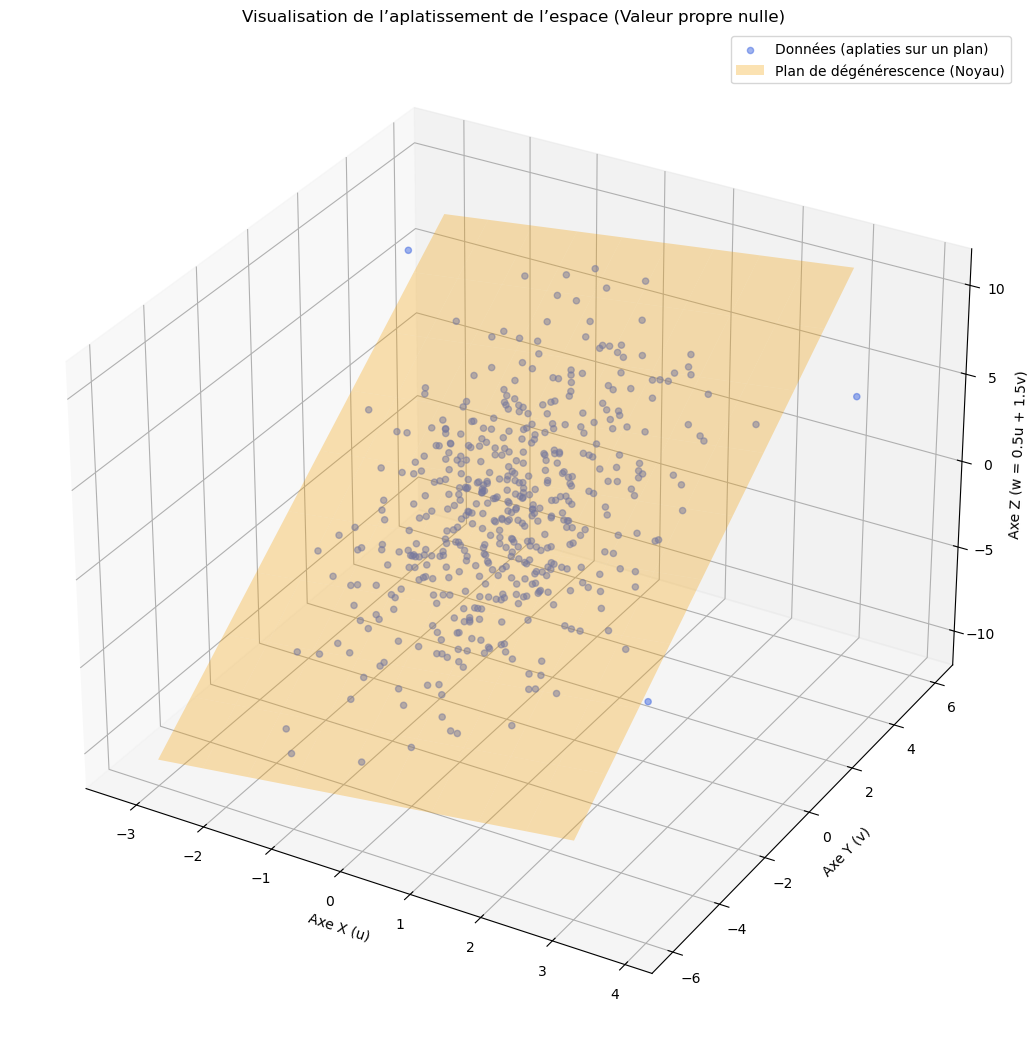

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Génération d'un jeu de données en dimension 3 avec une redondance parfaite
np.random.seed(42)
n = 500

# Deux variables indépendantes de base
u = np.random.normal(0, 1, n)
v = np.random.normal(0, 2, n)

# La troisième dimension est une combinaison linéaire exacte des deux autres
# Cela crée une colinéarité parfaite -> la matrice de covariance sera semi-définie positive
w = 0.5 * u + 1.5 * v 

# Matrice de données de taille (n x 3)
data = np.column_stack((u, v, w))

# 2. Calcul de la matrice de covariance et de ses valeurs propres
Sigma = np.cov(data, rowvar=False)
eigenvalues = np.linalg.eigvalsh(Sigma)

print("Matrice de covariance Sigma :\n", np.round(Sigma, 4))
print("\nValeurs propres de Sigma (notez la première proche de 0) :\n", eigenvalues)

# 3. Calcul du pseudo-inverse de Moore-Penrose (Sigma+)
Sigma_plus = np.linalg.pinv(Sigma)
print("\nPseudo-inverse Sigma+ calculé avec succès.")

# 4. Visualisation 3D avec Matplotlib
fig = plt.figure(figsize=(13, 15))
ax = fig.add_subplot(projection='3d')

# Nuage de points (qui s'aplatit sur un plan)
ax.scatter(data[:, 0], data[:, 1], data[:, 2], color='royalblue', alpha=0.5, s=20, label='Données (aplaties sur un plan)')

# Création d'une grille pour visualiser le plan géométrique de l'aplatissement
uu = np.linspace(-3, 3, 10)
vv = np.linspace(-6, 6, 10)
UU, VV = np.meshgrid(uu, vv)
WW = 0.5 * UU + 1.5 * VV

ax.plot_surface(UU, VV, WW, color='orange', alpha=0.3, edgecolor='none', label='Plan de dégénérescence (Noyau)')

ax.set_xlabel('Axe X (u)')
ax.set_ylabel('Axe Y (v)')
ax.set_zlabel('Axe Z (w = 0.5u + 1.5v)')
ax.set_title('Visualisation de l’aplatissement de l’espace (Valeur propre nulle)')
ax.legend()

plt.show()

# Suppression des données linéairement corrélées via l'agorithme du Principal Component ANalysis:

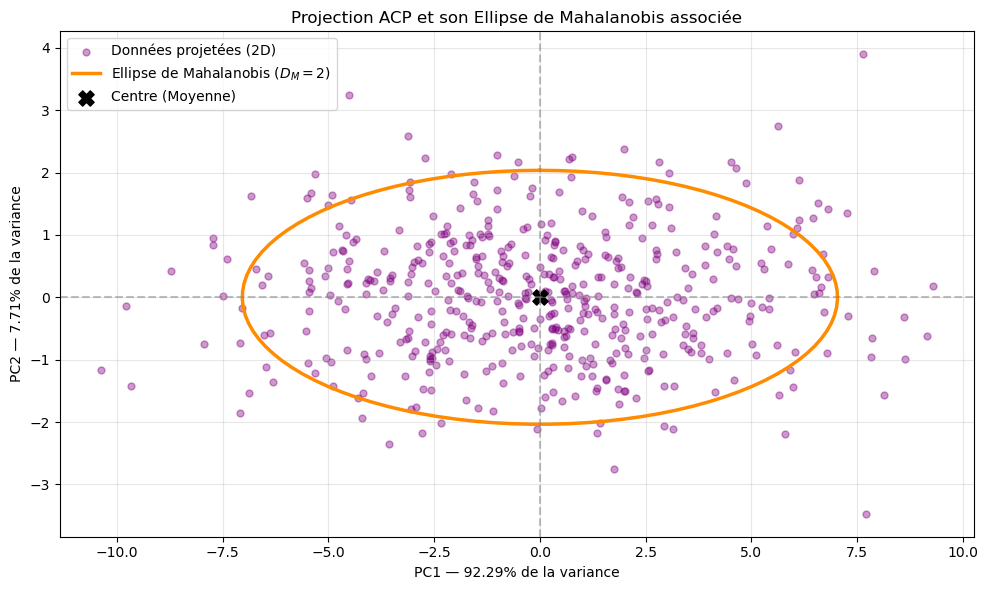

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Génération du jeu de données en dimension 3 avec une redondance parfaite
np.random.seed(42)
n = 500

u = np.random.normal(0, 1, n)
v = np.random.normal(0, 2, n)
w = 0.5 * u + 1.5 * v  # Colinéarité parfaite

data = np.column_stack((u, v, w))

# 2. Application de l'ACP pour réduire de 3D à 2D
pca = PCA(n_components=2)
data_2d = pca.fit_transform(data)

# Récupération de la variance expliquée en pourcentage pour chaque axe
explained_variance = pca.explained_variance_ratio_ * 100

# 3. Calcul de la moyenne et de la matrice de covariance dans l'espace réduit 2D
mean_2d = np.mean(data_2d, axis=0)
Sigma_2d = np.cov(data_2d, rowvar=False)

# Fonction utilitaire pour générer les points de l'ellipse de Mahalanobis (D_M = 2)
def get_ellipse_pts(mean, Sigma, radius=2.0, resolution=100):
    theta = np.linspace(0, 2 * np.pi, resolution)
    circle_pts = np.array([np.cos(theta), np.sin(theta)])
    
    eigenvals, eigenvectors = np.linalg.eigh(Sigma)
    ellipse_pts = eigenvectors @ np.diag(np.sqrt(eigenvals)) @ circle_pts * radius
    
    X_ell = ellipse_pts[0] + mean[0]
    Y_ell = ellipse_pts[1] + mean[1]
    return X_ell, Y_ell

X_ell, Y_ell = get_ellipse_pts(mean_2d, Sigma_2d, radius=2.0)

# 4. Visualisation 2D : Nuage de points projetés + Ellipse de Mahalanobis
plt.figure(figsize=(10, 6))
plt.scatter(data_2d[:, 0], data_2d[:, 1], color='purple', alpha=0.4, s=25, label='Données projetées (2D)')
plt.plot(X_ell, Y_ell, color='darkorange', linewidth=2.5, label='Ellipse de Mahalanobis ($D_M = 2$)')
plt.scatter([mean_2d[0]], [mean_2d[1]], color='black', s=120, marker='X', label='Centre (Moyenne)')

plt.title("Projection ACP et son Ellipse de Mahalanobis associée")

# Intégration dynamique des pourcentages de variance expliquée sur les axes
plt.xlabel(f"PC1 — {explained_variance[0]:.2f}% de la variance")
plt.ylabel(f"PC2 — {explained_variance[1]:.2f}% de la variance")

plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.5)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Ajout dans la définition du caractère défini positif:

Soit $\Sigma$ une matrice de covariance **définie strictement positive** (PD) de taille $n \times n$. Puisqu'elle est inversible (son déterminant est strictement positif, $\det(\Sigma) > 0$), son inverse classique $\Sigma^{-1}$ existe de manière unique.

Le **produit scalaire** associé à cette matrice inverse est l'application qui, à tout couple de vecteurs $(x, y) \in \mathbb{R}^n \times \mathbb{R}^n$, associe le nombre réel :

$$\langle x, y \rangle_{\Sigma^{-1}} = x^T \Sigma^{-1} y$$

---

# Vérification des Axiomes

Pour qu'une telle formulation qualifie un véritable produit scalaire au sens strict, elle respecte l'ensemble des propriétés structurelles :

1. **La Bilinéarité :**
Elle reste parfaitement valide. Par la distributivité du produit matriciel :

$$\langle ax_1 + bx_2, y \rangle_{\Sigma^{-1}} = (ax_1 + bx_2)^T \Sigma^{-1} y = a(x_1^T \Sigma^{-1} y) + b(x_2^T \Sigma^{-1} y) = a\langle x_1, y \rangle_{\Sigma^{-1}} + b\langle x_2, y \rangle_{\Sigma^{-1}}$$

2. **La Symétrie :**
Elle est conservée car l'inverse d'une matrice symétrique ($\Sigma$) est lui-même symétrique ($(\Sigma^{-1})^T = \Sigma^{-1}$).

$$\langle x, y \rangle_{\Sigma^{-1}} = x^T \Sigma^{-1} y = (x^T \Sigma^{-1} y)^T = y^T (\Sigma^{-1})^T x = y^T \Sigma^{-1} x = \langle y, x \rangle_{\Sigma^{-1}}$$

3. **La Positivité Stricte (Définie positive) :**
Puisque $\Sigma^{-1}$ est une matrice définie positive, on a la positivité :

$$\langle x, x \rangle_{\Sigma^{-1}} = x^T \Sigma^{-1} x \ge 0$$

Contrairement au cas semi-défini, **l'implication stricte est pleinement respectée** :


$$\langle x, x \rangle_{\Sigma^{-1}} = 0 \iff x = 0$$


Aucun vecteur non nul ne peut donner zéro. Il n'existe aucune direction de variance nulle, car l'espace ne souffre d'aucune redondance linéaire parfaite.

---

# Conséquence sur la Distance

Ce produit scalaire induit directement la **distance de Mahalanobis classique** :

$$D_M(x, y) = \sqrt{\langle x - y, x - y \rangle_{\Sigma^{-1}}} = \sqrt{(x - y)^T \Sigma^{-1} (x - y)}$$

Géométriquement parlant, l'espace forme un **hyper-ellipsoïde parfait et non dégénéré** en dimension $n$. Chaque dimension possède un volume et une épaisseur réels, garantissant que la distance entre deux points distincts est toujours strictement positive.

Matrice de covariance Sigma (définie strictement positive) :
 [[ 1.9626  4.2504  1.7826]
 [ 4.2504 14.9582  6.2156]
 [ 1.7826  6.2156  2.9232]]

Valeurs propres de Sigma (toutes strictement > 0) :
 [ 0.28874029  0.70530709 18.84989325]

Matrice inverse Sigma^-1 calculée avec succès.


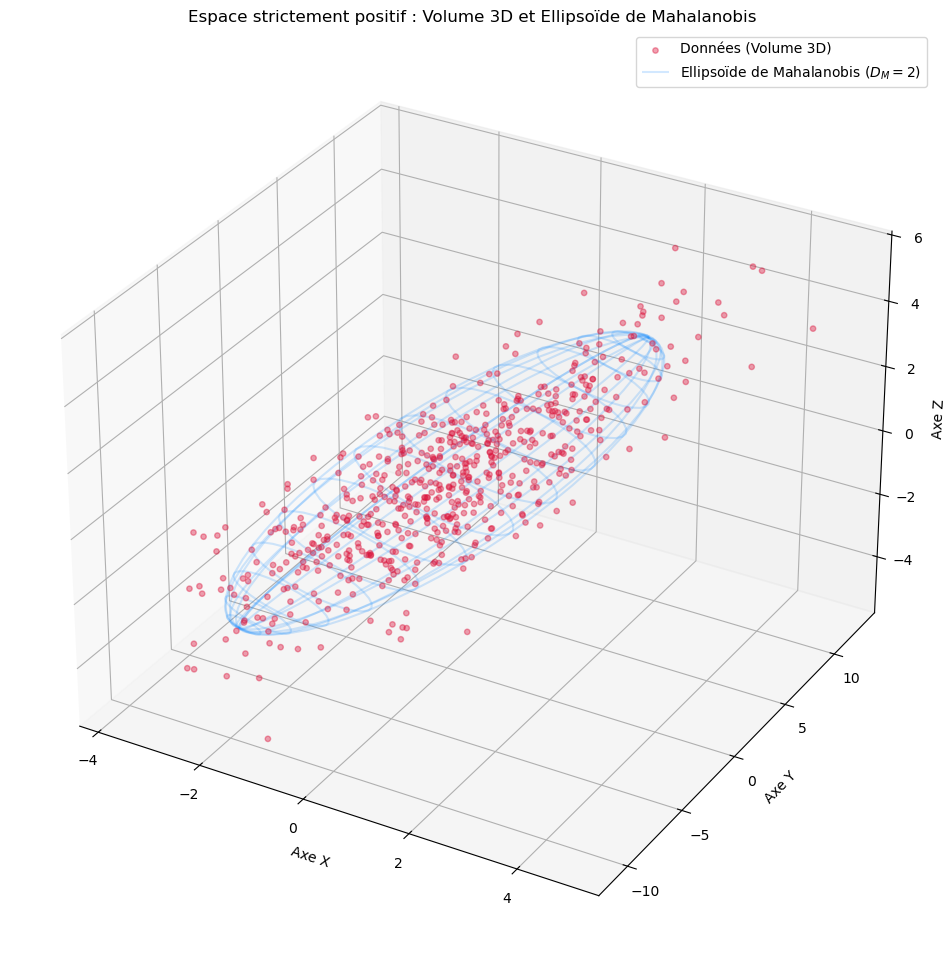

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Génération de données en dimension 3 linéairement indépendantes
np.random.seed(0)
n = 600

# Génération de variables indépendantes avec des variances différentes
x1 = np.random.normal(0, 1, n)
x2 = np.random.normal(0, 2, n)
x3 = np.random.normal(0, 0.5, n)

# On introduit des corrélations via une transformation linéaire non-singulière
# pour obtenir une matrice de covariance quelconque mais inversible
data_raw = np.column_stack((x1, x2, x3))
A = np.array([[1.0, 0.5, 0.2], 
              [0.5, 2.0, 0.8], 
              [0.2, 0.8, 1.5]])
data = data_raw @ A

# 2. Calcul de la matrice de covariance et vérification des valeurs propres
Sigma = np.cov(data, rowvar=False)
eigenvalues = np.linalg.eigvalsh(Sigma)

print("Matrice de covariance Sigma (définie strictement positive) :\n", np.round(Sigma, 4))
print("\nValeurs propres de Sigma (toutes strictement > 0) :\n", eigenvalues)

# L'inverse classique (Sigma^-1) existe sans aucun problème !
Sigma_inv = np.linalg.inv(Sigma)
print("\nMatrice inverse Sigma^-1 calculée avec succès.")

# 3. Visualisation 3D du volume et de l'ellipsoïde de Mahalanobis
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')

# Nuage de points (volume 3D complet)
ax.scatter(data[:, 0], data[:, 1], data[:, 2], color='crimson', alpha=0.4, s=15, label='Données (Volume 3D)')

# --- Génération de l'ellipsoïde de Mahalanobis (distance constante) ---
# Paramétrique d'une sphère unité
u_sphere = np.linspace(0, 2 * np.pi, 30)
v_sphere = np.linspace(0, np.pi, 30)
xx = np.outer(np.cos(u_sphere), np.sin(v_sphere))
yy = np.outer(np.sin(u_sphere), np.sin(v_sphere))
zz = np.outer(np.ones_like(u_sphere), np.cos(v_sphere))
sphere_points = np.array([xx.flatten(), yy.flatten(), zz.flatten()])

# Décomposition spectrale de Sigma pour étirer la sphère en ellipsoïde selon la covariance
eigenvalues_matrix, eigenvectors = np.linalg.eigh(Sigma)
# Rayon de l'ellipsoïde pour un niveau de confiance donné (ex: D_M = 2)
radius = 2.0 
ellipsoid_points = eigenvectors @ np.diag(np.sqrt(eigenvalues_matrix)) @ sphere_points * radius

# Recentrage sur la moyenne des données
mean = np.mean(data, axis=0)
X_ell = ellipsoid_points[0, :].reshape(xx.shape) + mean[0]
Y_ell = ellipsoid_points[1, :].reshape(yy.shape) + mean[1]
Z_ell = ellipsoid_points[2, :].reshape(zz.shape) + mean[2]

# Tracé de l'ellipsoïde de Mahalanobis
ax.plot_wireframe(X_ell, Y_ell, Z_ell, color='dodgerblue', alpha=0.2, rstride=2, cstride=2, label='Ellipsoïde de Mahalanobis ($D_M = 2$)')

ax.set_xlabel('Axe X')
ax.set_ylabel('Axe Y')
ax.set_zlabel('Axe Z')
ax.set_title('Espace strictement positif : Volume 3D et Ellipsoïde de Mahalanobis')
ax.legend()

plt.show()


# Théorème

Soit un vecteur aléatoire $X = (X_1, X_2, \dots, X_n)^T$ suivant une loi normale multivariée de moyenne $\mu$ et de matrice de covariance strictement positive $\Sigma$ :


$$X \sim \mathcal{N}(\mu, \Sigma)$$

Le carré de sa distance de Mahalanobis par rapport à sa moyenne, noté $D_M^2$, suit une loi du $\chi^2$ à $n$ degrés de liberté :


$$D_M(X, \mu)^2 = (X - \mu)^T \Sigma^{-1} (X - \mu) \sim \chi^2_n$$

# Démonstration

### Étape 1 : Centrage du vecteur aléatoire

Commençons par définir le vecteur centré $Y$ en soustrayant la moyenne $\mu$ :


$$Y = X - \mu$$

Puisque $X$ suit une loi normale $\mathcal{N}(\mu, \Sigma)$, sa translation $Y$ suit naturellement une loi normale centrée de même matrice de covariance :


$$Y \sim \mathcal{N}(0, \Sigma)$$

Le carré de la distance de Mahalanobis s'écrit alors simplement en fonction de $Y$ :


$$D_M^2 = Y^T \Sigma^{-1} Y$$

---

### Étape 2 : Utilisation de la racine carrée de la matrice de covariance

Puisque $\Sigma$ est une matrice symétrique définie strictement positive, elle admet une décomposition spectrale (ou une racine carrée matricielle symétrique) que l'on peut noter $\Sigma^{1/2}$.

Son inverse $\Sigma^{-1}$ peut lui aussi être décomposé sous la forme :


$$\Sigma^{-1} = (\Sigma^{-1/2})^T \Sigma^{-1/2} = \Sigma^{-1/2} \Sigma^{-1/2} \quad (\text{car } \Sigma \text{ est symétrique})$$

Injectons cette expression dans notre carré de distance :


$$D_M^2 = Y^T \left( \Sigma^{-1/2} \Sigma^{-1/2} \right) Y$$

Par associativité du produit matriciel, on peut regrouper les termes :


$$D_M^2 = \left( \Sigma^{-1/2} Y \right)^T \left( \Sigma^{-1/2} Y \right)$$

---

### Étape 3 : Le "blanchiment" et passage à une loi normale standard

Posons un nouveau vecteur aléatoire $Z$ défini par la transformation linéaire :


$$Z = \Sigma^{-1/2} Y$$

Étudions la distribution de ce nouveau vecteur $Z$ :

1. **Espérance mathématique :**

$$\mathbb{E}[Z] = \Sigma^{-1/2} \mathbb{E}[Y] = \Sigma^{-1/2} \times 0 = 0$$


2. **Matrice de covariance :**

$$\text{Cov}(Z) = \Sigma^{-1/2} \text{Cov}(Y) (\Sigma^{-1/2})^T = \Sigma^{-1/2} \Sigma \Sigma^{-1/2}$$



Puisque $\Sigma = \Sigma^{1/2}\Sigma^{1/2}$ et que $\Sigma^{-1/2}$ est l'inverse de cette matrice, on obtient :

$$\text{Cov}(Z) = I_n$$



où $I_n$ est la matrice identité de taille $n \times n$.

**Conclusion intermédiaire :** Le vecteur $Z$ est le fruit d'une transformation linéaire d'un vecteur gaussien, il suit donc lui aussi une loi normale. Plus précisément, ses composantes sont de moyenne nulle, de variance 1, et **totalement indépendantes** :


$$Z = \begin{pmatrix} Z_1 \\ Z_2 \\ \vdots \\ Z_n \end{pmatrix} \sim \mathcal{N}(0, I_n)$$


avec $Z_i \sim \mathcal{N}(0, 1)$ pour tout $i \in \{1, \dots, n\}$.

---

### Étape 4 : Expression finale et conclusion

Revenons à l'expression de notre distance de Mahalanobis $D_M^2$ exprimée avec le vecteur $Z$ :


$$D_M^2 = Z^T Z$$

En développant ce produit matriciel sous forme de somme de composantes :


$$D_M^2 = \sum_{i=1}^{n} Z_i^2$$

* **Le constat final :** $D_M^2$ est égal à la somme des carrés de $n$ variables aléatoires indépendantes suivant toutes une loi normale centrée réduite $\mathcal{N}(0, 1)$.
* **Par définition mathématique stricte**, la somme de $n$ carrés de variables $\mathcal{N}(0, 1)$ indépendantes suit par construction une **loi du $\chi^2$ à $n$ degrés de liberté** ($\chi^2_n$).

$$\mathbf{D_M(X, \mu)^2 \sim \chi^2_n}$$



### Théorème:

Soit un vecteur aléatoire $X \in \mathbb{R}^n$ de moyenne $\mu$ et de matrice de covariance strictement positive $\Sigma$.
Soit une transformation affine inversible $Y$ définie par :


$$Y = A X + b$$


où $A$ est une matrice carrée inversible de taille $n \times n$ et $b$ un vecteur constant de dimension $n$.

Démontrons que la distance de Mahalanobis de $Y$ par rapport à sa moyenne $\mu_Y$ est **strictement égale** à la distance de Mahalanobis de $X$ par rapport à $\mu$ :


$$D_M(Y, \mu_Y)^2 = D_M(X, \mu)^2$$

---

### Étape 1 : Calcul de la nouvelle moyenne et de la nouvelle covariance

1. **La moyenne de $Y$ ($\mu_Y$) :**
Par linéarité de l'espérance mathématique :

$$\mu_Y = \mathbb{E}[A X + b] = A \mathbb{E}[X] + b = A \mu + b$$


2. **Le vecteur centré $Y - \mu_Y$ :**
Faisons la différence entre $Y$ et sa moyenne :

$$Y - \mu_Y = (A X + b) - (A \mu + b) = A X - A \mu = A(X - \mu)$$


3. **La matrice de covariance de $Y$ ($\Sigma_Y$) :**
Par définition de la variance d'une transformation linéaire :

$$\Sigma_Y = \text{Cov}(A X + b) = A \text{Cov}(X) A^T = A \Sigma A^T$$



---

### Étape 2 : Inversion de la nouvelle matrice de covariance

Puisque $\Sigma$ est inversible et que $A$ est une matrice carrée inversible, le produit $A \Sigma A^T$ est également inversible.

Rappelons la règle d'inversion d'un produit de matrices : $(M N)^{-1} = N^{-1} M^{-1}$, et la propriété de la transposée : $(M^T)^{-1} = (M^{-1})^T$.

Appliquons cela pour trouver l'inverse $\Sigma_Y^{-1}$ :


$$\Sigma_Y^{-1} = (A \Sigma A^T)^{-1} = (A^T)^{-1} \Sigma^{-1} A^{-1}$$


En réécrivant $(A^T)^{-1}$ sous la forme $(A^{-1})^T$ :


$$\Sigma_Y^{-1} = (A^{-1})^T \Sigma^{-1} A^{-1}$$

---

### Étape 3 : Réinjection dans le carré de la distance de Mahalanobis

Exprimons maintenant le carré de la distance de Mahalanobis dans l'espace transformé $Y$ :


$$D_M(Y, \mu_Y)^2 = (Y - \mu_Y)^T \Sigma_Y^{-1} (Y - \mu_Y)$$

Remplaçons $Y - \mu_Y$ par $A(X - \mu)$ et $\Sigma_Y^{-1}$ par son expression trouvée à l'étape 2 :


$$D_M(Y, \mu_Y)^2 = \left[ A(X - \mu) \right]^T \left[ (A^{-1})^T \Sigma^{-1} A^{-1} \right] \left[ A(X - \mu) \right]$$

Utilisons la règle de transposition d'un produit $(AB)^T = B^T A^T$ sur le premier terme :


$$[A(X - \mu)]^T = (X - \mu)^T A^T$$

L'expression devient :


$$D_M(Y, \mu_Y)^2 = (X - \mu)^T \underbrace{A^T (A^{-1})^T}_{I} \Sigma^{-1} \underbrace{A^{-1} A}_{I} (X - \mu)$$

Puisque $A^T (A^{-1})^T = (A^{-1} A)^T = I^T = I$ (la matrice identité) et que $A^{-1} A = I$, les termes se simplifient élégamment :


$$D_M(Y, \mu_Y)^2 = (X - \mu)^T I \Sigma^{-1} I (X - \mu)$$

$$D_M(Y, \mu_Y)^2 = (X - \mu)^T \Sigma^{-1} (X - \mu)$$

---

### Conclusion

$$\mathbf{D_M(Y, \mu_Y)^2 = D_M(X, \mu)^2}$$

CQFD.

**Portée pratique en finance :**
Peu importe que vous analysiez le risque d'un portefeuille dans l'espace brut des prix des actions ou après une rotation de facteurs (comme une ACP ou une orthogonalisation de Cholesky), **la mesure du risque d'anomalie ou d'éloignement par rapport à l'équilibre reste rigoureusement la même**.

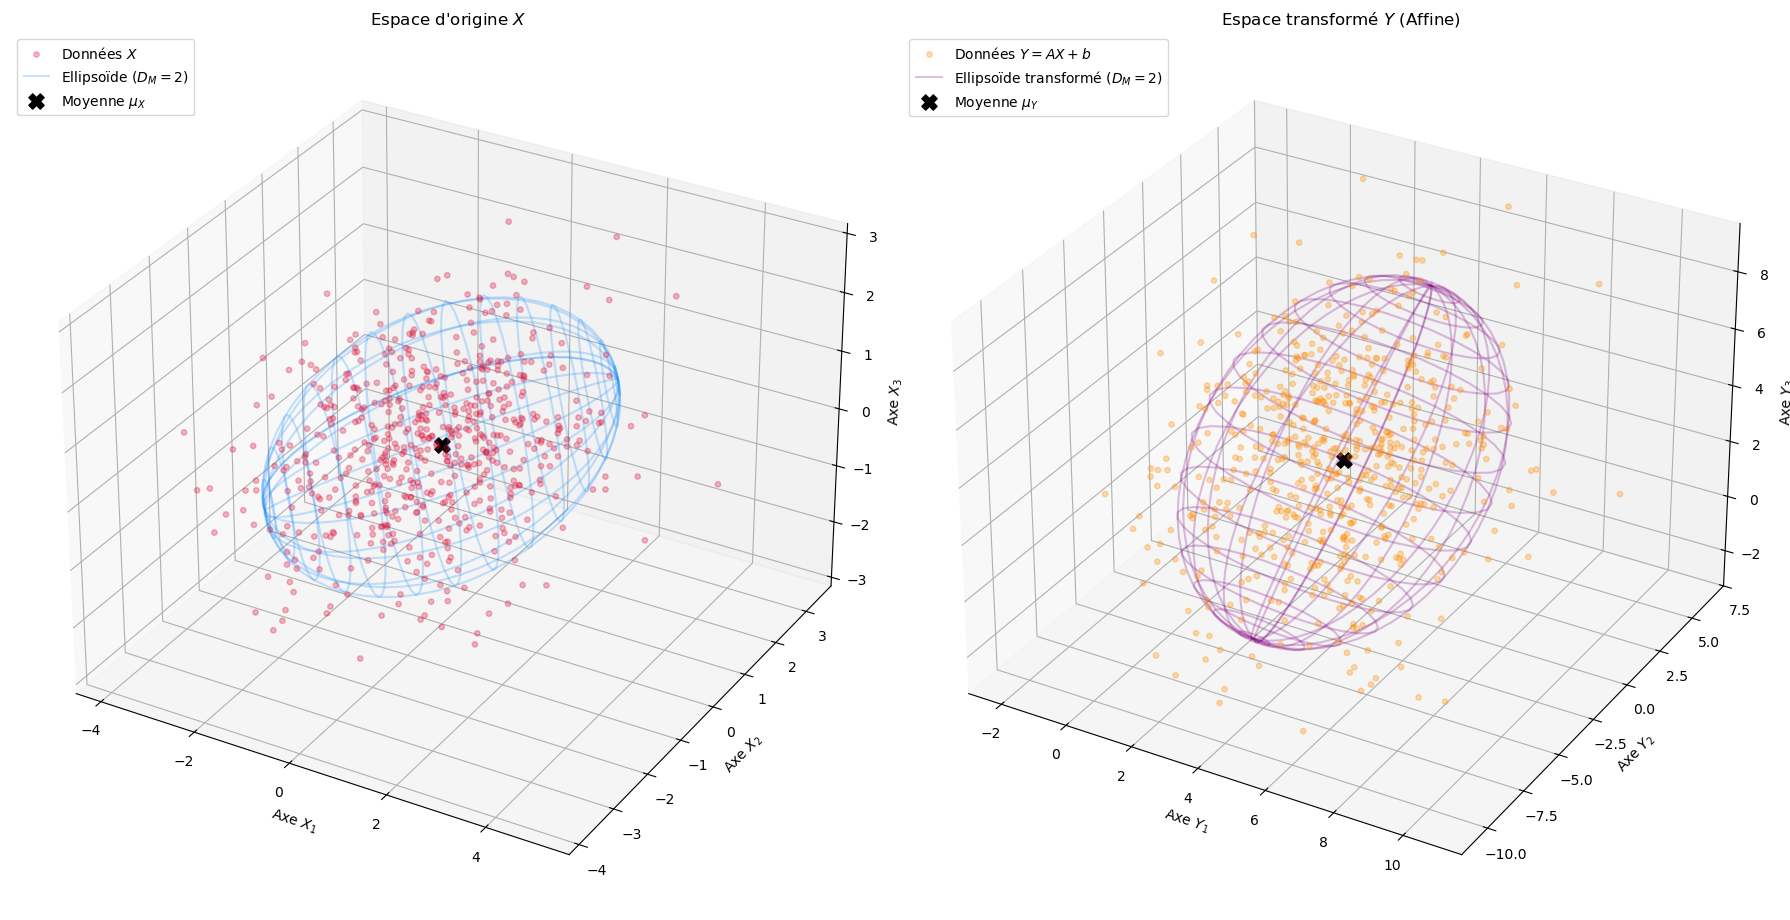

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Génération des données dans l'espace d'origine X
np.random.seed(42)
n_samples = 600

Sigma_X = np.array([[2.0, 0.5, 0.2],
                    [0.5, 1.5, 0.4],
                    [0.2, 0.4, 1.0]])
mean_X = np.array([0.0, 0.0, 0.0])

# Données suivant N(mu_X, Sigma_X)
X = np.random.multivariate_normal(mean_X, Sigma_X, n_samples)

# 2. Définition de la transformation affine Y = A X + b
A = np.array([[1.5, -0.8, 0.2],
              [0.3,  2.0, 1.0],
              [-0.2, 0.5, 1.8]])
b = np.array([4.0, -2.0, 3.0])

# Application de la transformation affine
Y = X @ A.T + b
mean_Y = A @ mean_X + b
Sigma_Y = A @ Sigma_X @ A.T

# 3. Fonction utilitaire pour générer un ellipsoïde de Mahalanobis
def get_ellipsoid_mesh(mean, Sigma, radius=2.0, resolution=30):
    u = np.linspace(0, 2 * np.pi, resolution)
    v = np.linspace(0, np.pi, resolution)
    xx = np.outer(np.cos(u), np.sin(v))
    yy = np.outer(np.sin(u), np.sin(v))
    zz = np.outer(np.ones_like(u), np.cos(v))
    sphere_pts = np.array([xx.flatten(), yy.flatten(), zz.flatten()])
    
    eigenvals, eigenvectors = np.linalg.eigh(Sigma)
    ellipsoid_pts = eigenvectors @ np.diag(np.sqrt(eigenvals)) @ sphere_pts * radius
    
    X_ell = ellipsoid_pts[0].reshape(xx.shape) + mean[0]
    Y_ell = ellipsoid_pts[1].reshape(yy.shape) + mean[1]
    Z_ell = ellipsoid_pts[2].reshape(zz.shape) + mean[2]
    return X_ell, Y_ell, Z_ell

# Maillage des ellipsoïdes pour D_M = 2 dans les deux espaces
X_ell, Y_ell, Z_ell = get_ellipsoid_mesh(mean_X, Sigma_X, radius=2.0)
Y_ell_x, Y_ell_y, Y_ell_z = get_ellipsoid_mesh(mean_Y, Sigma_Y, radius=2.0)

# 4. Visualisation comparative en 3D (Double subplot)
fig = plt.figure(figsize=(18, 12))

# --- Graphique 1 : Espace X ---
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(X[:, 0], X[:, 1], X[:, 2], color='crimson', alpha=0.3, s=15, label='Données $X$')
ax1.plot_wireframe(X_ell, Y_ell, Z_ell, color='dodgerblue', alpha=0.25, rstride=2, cstride=2, label='Ellipsoïde ($D_M = 2$)')
ax1.scatter([mean_X[0]], [mean_X[1]], [mean_X[2]], color='black', s=120, marker='X', label='Moyenne $\mu_X$')
ax1.set_title("Espace d'origine $X$")
ax1.set_xlabel('Axe $X_1$')
ax1.set_ylabel('Axe $X_2$')
ax1.set_zlabel('Axe $X_3$')
ax1.legend(loc='upper left')

# --- Graphique 2 : Espace Y transformé ---
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(Y[:, 0], Y[:, 1], Y[:, 2], color='darkorange', alpha=0.3, s=15, label='Données $Y = AX + b$')
ax2.plot_wireframe(Y_ell_x, Y_ell_y, Y_ell_z, color='purple', alpha=0.25, rstride=2, cstride=2, label='Ellipsoïde transformé ($D_M = 2$)')
ax2.scatter([mean_Y[0]], [mean_Y[1]], [mean_Y[2]], color='black', s=120, marker='X', label='Moyenne $\mu_Y$')
ax2.set_title("Espace transformé $Y$ (Affine)")
ax2.set_xlabel('Axe $Y_1$')
ax2.set_ylabel('Axe $Y_2$')
ax2.set_zlabel('Axe $Y_3$')
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

# Différence entre la distance L1 (de Manhattan), L2 (Euclidienne) et de Manhalanobis


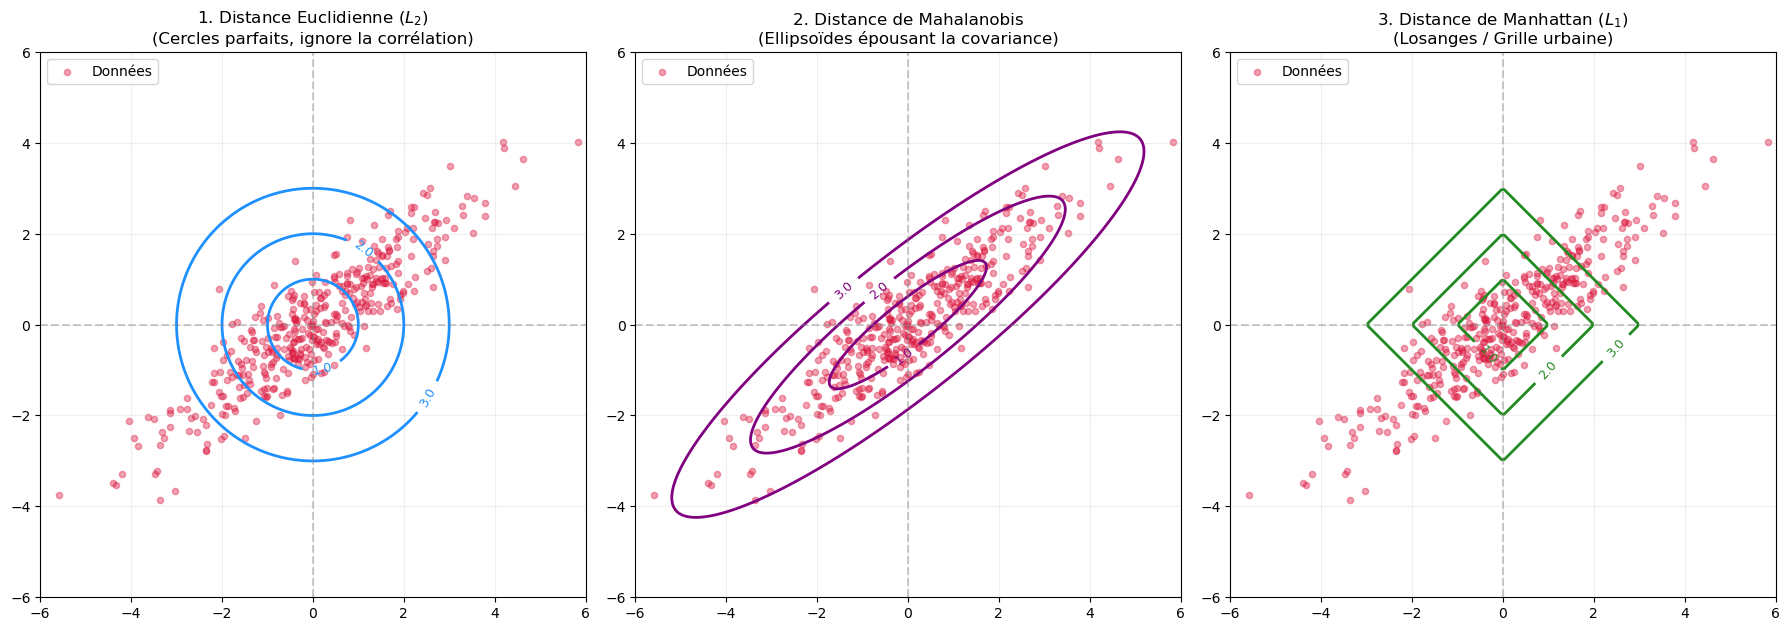

In [15]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Génération d'un même jeu de données corrélé en dimension 2
np.random.seed(42)
n_samples = 400
mean = np.array([0, 0])
# Matrice de covariance fortement corrélée
Sigma = np.array([[3.0, 2.2], 
                  [2.2, 2.0]]) 

data = np.random.multivariate_normal(mean, Sigma, n_samples)

# Grille de calcul pour les contours
x = np.linspace(-6, 6, 200)
y = np.linspace(-6, 6, 200)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))

# --- Calcul des 3 distances par rapport au centre (0,0) ---
# 1. Distance Euclidienne : sqrt(x^2 + y^2)
Z_euc = np.sqrt(X**2 + Y**2)

# 2. Distance de Mahalanobis : sqrt((x-mu)^T Sigma^-1 (x-mu))
inv_Sigma = np.linalg.inv(Sigma)
diff = pos - mean
Z_mah = np.sqrt(np.einsum('ijk,kl,ijl->ij', diff, inv_Sigma, diff))

# 3. Distance de Manhattan : |x| + |y|
Z_man = np.abs(X) + np.abs(Y)

# 2. Visualisation comparative en 1x3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Niveaux de distance à tracer
levels = [1.0, 2.0, 3.0]

# --- Graphique 1 : Euclidienne ---
axes[0].scatter(data[:, 0], data[:, 1], color='crimson', alpha=0.4, s=20, label='Données')
cs0 = axes[0].contour(X, Y, Z_euc, levels=levels, colors='dodgerblue', linewidths=2)
axes[0].clabel(cs0, inline=True, fontsize=9, fmt='%.1f')
axes[0].set_title('1. Distance Euclidienne ($L_2$)\n(Cercles parfaits, ignore la corrélation)')
axes[0].axhline(0, color='gray', linestyle='--', alpha=0.4)
axes[0].axvline(0, color='gray', linestyle='--', alpha=0.4)

# --- Graphique 2 : Mahalanobis ---
axes[1].scatter(data[:, 0], data[:, 1], color='crimson', alpha=0.4, s=20, label='Données')
cs1 = axes[1].contour(X, Y, Z_mah, levels=levels, colors='purple', linewidths=2)
axes[1].clabel(cs1, inline=True, fontsize=9, fmt='%.1f')
axes[1].set_title('2. Distance de Mahalanobis\n(Ellipsoïdes épousant la covariance)')
axes[1].axhline(0, color='gray', linestyle='--', alpha=0.4)
axes[1].axvline(0, color='gray', linestyle='--', alpha=0.4)

# --- Graphique 3 : Manhattan ---
axes[2].scatter(data[:, 0], data[:, 1], color='crimson', alpha=0.4, s=20, label='Données')
cs2 = axes[2].contour(X, Y, Z_man, levels=levels, colors='forestgreen', linewidths=2)
axes[2].clabel(cs2, inline=True, fontsize=9, fmt='%.1f')
axes[2].set_title('3. Distance de Manhattan ($L_1$)\n(Losanges / Grille urbaine)')
axes[2].axhline(0, color='gray', linestyle='--', alpha=0.4)
axes[2].axvline(0, color='gray', linestyle='--', alpha=0.4)

# Mise en forme globale
for ax in axes:
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

Point   | Coût L1 (Manhattan)  | Coût L2 (Euclidien²)  | Coût Mahalanobis  
--------------------------------------------------------------------------
#1      | 1.3142               | 0.8731                | 0.2658            
#2      | 1.7136               | 2.6281                | 2.7391            
#3      | 0.6195               | 0.2193                | 0.1096            
#4      | 4.1782               | 9.0232                | 3.0829            
#5      | 1.2421               | 0.9186                | 0.5148            
#6      | 1.2261               | 0.8601                | 0.4317            
#7      | 1.9133               | 2.0352                | 3.7192            
#8      | 4.5637               | 10.5718               | 3.2915            
#9      | 2.6797               | 3.6398                | 1.1246            
#10     | 2.4024               | 3.8831                | 2.8191            
#11     | 3.8777               | 7.5439                | 2.1991            
#12     | 1.4

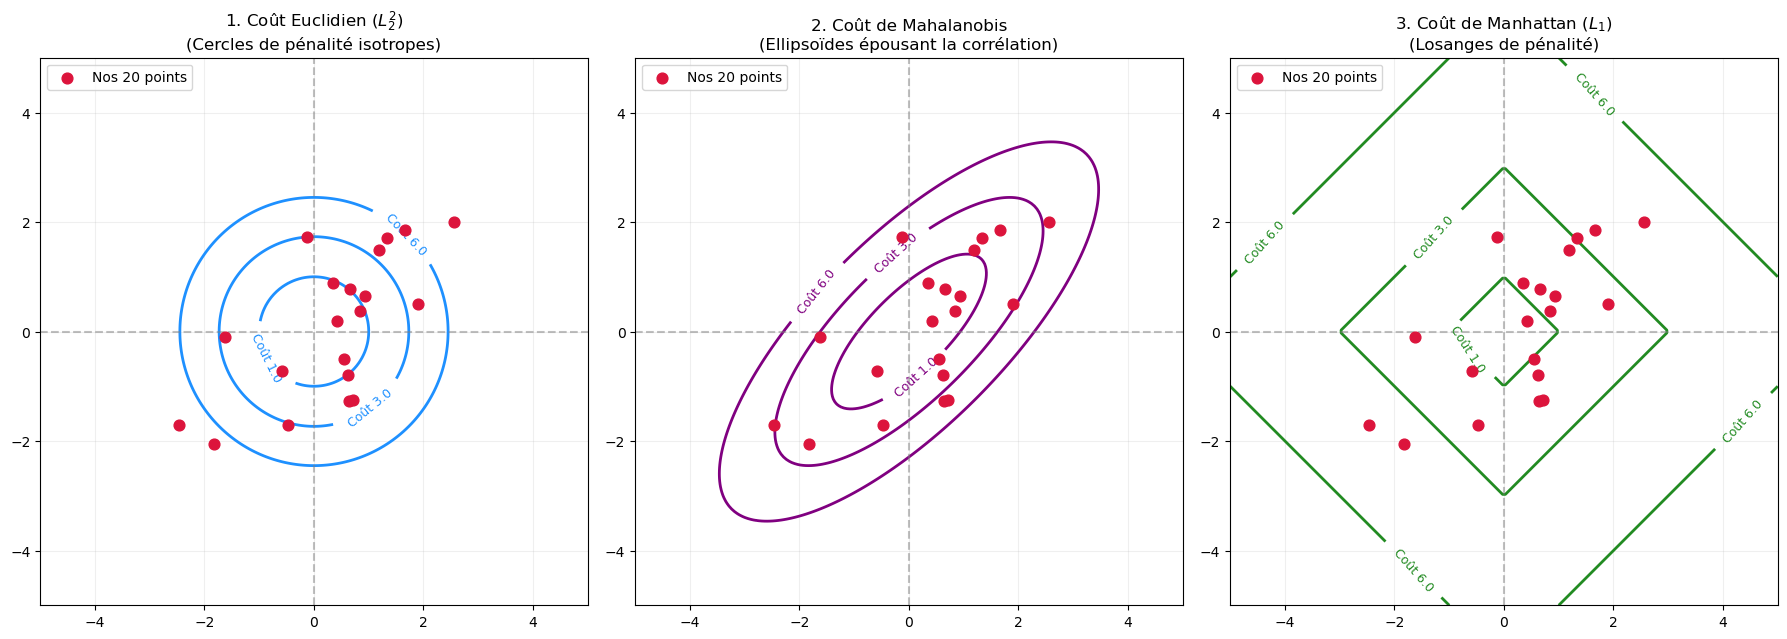

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Génération de 20 points aléatoires dans un espace 2D corrélé
np.random.seed(42)
n_samples = 20
mean = np.array([0.0, 0.0])
Sigma = np.array([[2.0, 1.5], 
                  [1.5, 2.0]]) # Matrice de covariance avec forte corrélation

X = np.random.multivariate_normal(mean, Sigma, n_samples)
ref_point = mean

# --- Calcul des fonctions de coût pour le tableau ---
l1_costs = np.sum(np.abs(X - ref_point), axis=1)
l2_costs = np.sum((X - ref_point)**2, axis=1)
inv_Sigma = np.linalg.inv(Sigma)
diff_pts = X - ref_point
mahalanobis_costs = np.einsum('ij,jk,ik->i', diff_pts, inv_Sigma, diff_pts)

# Affichage du tableau dans la console
print(f"{'Point':<7} | {'Coût L1 (Manhattan)':<20} | {'Coût L2 (Euclidien²)':<21} | {'Coût Mahalanobis':<18}")
print("-" * 74)
for i in range(n_samples):
    print(f"#{i+1:<6} | {l1_costs[i]:<20.4f} | {l2_costs[i]:<21.4f} | {mahalanobis_costs[i]:<18.4f}")

# 2. Grille pour tracer les lignes de niveau des coûts sur les graphiques
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)
X_grid, Y_grid = np.meshgrid(x, y)
pos = np.dstack((X_grid, Y_grid))

Z_l2 = X_grid**2 + Y_grid**2
diff_grid = pos - mean
Z_mah = np.einsum('ijk,kl,ijl->ij', diff_grid, inv_Sigma, diff_grid)
Z_l1 = np.abs(X_grid) + np.abs(Y_grid)

# 3. Tracé des graphiques comparatifs
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
levels = [1.0, 3.0, 6.0] # Niveaux de coût à visualiser

# --- Graphique 1 : Coût Euclidien (L2²) ---
axes[0].scatter(X[:, 0], X[:, 1], color='crimson', s=60, zorder=5, label='Nos 20 points')
cs0 = axes[0].contour(X_grid, Y_grid, Z_l2, levels=levels, colors='dodgerblue', linewidths=2)
axes[0].clabel(cs0, inline=True, fontsize=9, fmt='Coût %.1f')
axes[0].set_title("1. Coût Euclidien ($L_2^2$)\n(Cercles de pénalité isotropes)")

# --- Graphique 2 : Coût de Mahalanobis ---
axes[1].scatter(X[:, 0], X[:, 1], color='crimson', s=60, zorder=5, label='Nos 20 points')
cs1 = axes[1].contour(X_grid, Y_grid, Z_mah, levels=levels, colors='purple', linewidths=2)
axes[1].clabel(cs1, inline=True, fontsize=9, fmt='Coût %.1f')
axes[1].set_title("2. Coût de Mahalanobis\n(Ellipsoïdes épousant la corrélation)")

# --- Graphique 3 : Coût de Manhattan (L1) ---
axes[2].scatter(X[:, 0], X[:, 1], color='crimson', s=60, zorder=5, label='Nos 20 points')
cs2 = axes[2].contour(X_grid, Y_grid, Z_l1, levels=levels, colors='forestgreen', linewidths=2)
axes[2].clabel(cs2, inline=True, fontsize=9, fmt='Coût %.1f')
axes[2].set_title("3. Coût de Manhattan ($L_1$)\n(Losanges de pénalité)")

# Mise en forme commune
for ax in axes:
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.axvline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()